In [1]:
import sys, os, glob, time
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

UTENTE = 'martinopaoloni-ux'
BRANCH = 'M2-integrazione'

!rm -rf /content/MozartAI
!git clone -b {BRANCH} https://github.com/{UTENTE}/MozartAI.git /content/MozartAI
sys.path.insert(0, '/content/MozartAI/src')

from preprocessing import foto_a_righi
from model import carica_modello, riconosci_righi, foto_a_simboli
print("Import ok")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/MozartAI'...
remote: Enumerating objects: 100, done.
remote: Counting objects: 100% (100/100), done.
remote: Compressing objects: 100% (93/93), done.
remote: Total 100 (delta 41), reused 9 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (100/100), 7.48 MiB | 8.82 MiB/s, done.
Resolving deltas: 100% (41/41), done.
Import ok


In [2]:
CKPT = '/content/drive/MyDrive/MozartAI/checkpoints_v2'
model, id2tok = carica_modello(f'{CKPT}/best.pt')
print("Classi:", len(id2tok) + 1, "| altezza:", model.img_h, "| parametri:", sum(p.numel() for p in model.parameters()))

import torch
ck = torch.load(f'{CKPT}/last.pt', map_location='cpu', weights_only=False)
print("Epoche fatte:", ck['epoch'] + 1)
for riga in ck['history'][-3:]:
    print(riga)

Classi: 1782 | altezza: 128 | parametri: 4456662
Epoche fatte: 20
{'epoch': 18, 'train_loss': 0.012141905945970824, 'val_loss': 0.04749278402328491, 'val_ser': 0.008653846153846154}
{'epoch': 19, 'train_loss': 0.011465932813620097, 'val_loss': 0.04721670336276293, 'val_ser': 0.008570234113712374}
{'epoch': 20, 'train_loss': 0.011188773635970919, 'val_loss': 0.046835510976612565, 'val_ser': 0.008528428093645485}


In [3]:
import tarfile
from PIL import Image

ARCHIVE = '/content/drive/MyDrive/MozartAI/data/primus.tgz'
coppie, parziali = [], {}
with tarfile.open(ARCHIVE, 'r:gz') as tar:
    for m in tar:
        nome = os.path.basename(m.name)
        if not m.isfile() or nome.startswith('._'):
            continue
        cartella = os.path.dirname(m.name)
        if nome.endswith('.png'):
            parziali.setdefault(cartella, {})['img'] = np.array(Image.open(tar.extractfile(m)).convert('L'))
        elif nome.endswith('.semantic'):
            parziali.setdefault(cartella, {})['sem'] = tar.extractfile(m).read().decode('utf-8').split()
        d = parziali.get(cartella, {})
        if 'img' in d and 'sem' in d:
            coppie.append((d['img'], d['sem']))
            parziali.pop(cartella)
            if len(coppie) == 10:
                break

previsti = riconosci_righi([c[0] for c in coppie], model, id2tok)
identici = sum(p == c[1] for p, c in zip(previsti, coppie))
print(f"Identici alla risposta giusta: {identici} su {len(coppie)}")
print("GIUSTO :", ' '.join(coppie[0][1]))
print("MODELLO:", ' '.join(previsti[0]))

Identici alla risposta giusta: 9 su 10
GIUSTO : clef-C1 keySignature-FM timeSignature-2/2 gracenote-D5_eighth note-C5_half note-Bb4_half barline gracenote-Bb4_eighth note-A4_half. note-G4_quarter barline note-A4_quarter. note-Bb4_eighth note-A4_quarter note-G4_quarter barline note-F4_half. note-A4_eighth note-Bb4_eighth barline note-C5_half note-Bb4_half barline
MODELLO: clef-C1 keySignature-FM timeSignature-2/2 gracenote-D5_eighth note-C5_half note-Bb4_half barline gracenote-Bb4_eighth note-A4_half. note-G4_quarter barline note-A4_quarter. note-Bb4_eighth note-A4_quarter note-G4_quarter barline note-F4_half. note-A4_eighth note-Bb4_eighth barline note-C5_half note-Bb4_half barline


In [4]:
CARTELLA = '/content/drive/MyDrive/MozartAI/Foto Prova'
FOTO = sorted(f for ext in ('jpg', 'jpeg', 'png') for f in glob.glob(f'{CARTELLA}/*.{ext}'))

risultati = {}
t0 = time.time()
for f in FOTO:
    righi = foto_a_righi(f)
    simboli = riconosci_righi(righi, model, id2tok)
    risultati[os.path.basename(f)] = (righi, simboli)
    for i, s in enumerate(simboli):
        print(f"{os.path.basename(f)} | rigo {i + 1} | {len(s)} simboli")
        print("   ", ' '.join(s))
print(f"\n{time.time() - t0:.1f} secondi in totale")

# La funzione che la Issue richiede: da una foto ai simboli, in una sola chiamata
print(foto_a_simboli(FOTO[0], model, id2tok))

IMG_3276.jpeg | rigo 1 | 12 simboli
    clef-F3 keySignature-AbM timeSignature-6/4 gracenote-Eb3_quarter note-Bb3_half gracenote-Eb3_quarter barline gracenote-Eb3_quarter tie gracenote-Eb3_quarter gracenote-Eb3_quarter note-D3_half.
IMG_3277.jpeg | rigo 1 | 20 simboli
    clef-F4 keySignature-GM timeSignature-2/4 gracenote-A4_sixteenth timeSignature-4/4 barline gracenote-G4_sixteenth rest-quarter note-D#4_eighth. barline timeSignature-2/2 note-G4_eighth.. note-G4_eighth.. note-E4_eighth barline barline tie timeSignature-3/2 tie multirest-33
IMG_3278.jpeg | rigo 1 | 14 simboli
    clef-G2 keySignature-DM timeSignature-C note-B4_quarter gracenote-D4_eighth note-D4_quarter tie note-B4_quarter barline note-B4_quarter note-A4_quarter note-A4_quarter rest-quarter barline
IMG_3279.jpeg | rigo 1 | 21 simboli
    clef-F3 barline rest-quadruple_whole note-D3_quarter note-D3_quarter barline note-B2_eighth tie note-B2_whole barline rest-eighth rest-quadruple_whole rest-quadruple_whole note-F3_eigh

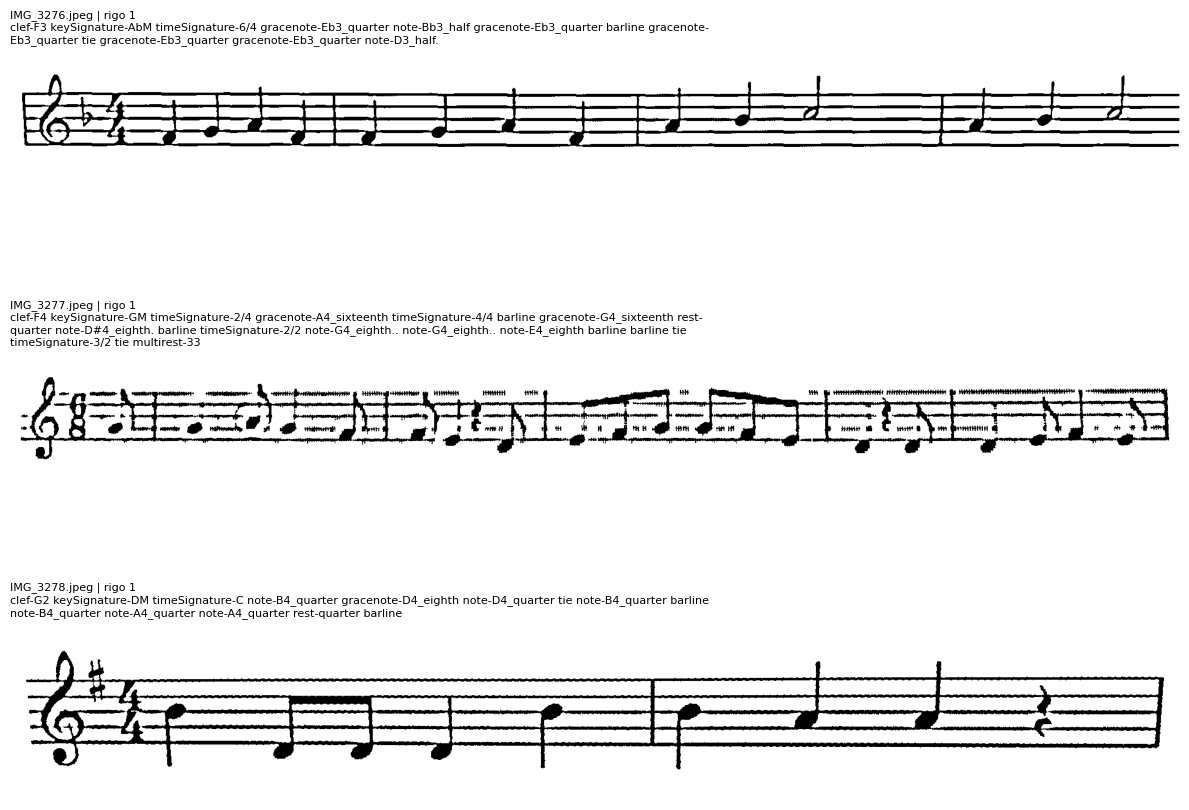

In [5]:
import textwrap
nomi = list(risultati)
scelti = [(nomi[0], 0), (nomi[1], 0), (nomi[2], 0)]      # CAMBIA gli indici in base ai righi che vuoi mostrare

fig, assi = plt.subplots(len(scelti), 1, figsize=(12, 3.2 * len(scelti)))
for ax, (nome, i) in zip(assi, scelti):
    righi, simboli = risultati[nome]
    ax.imshow(righi[i], cmap='gray'); ax.axis('off')
    ax.set_title(f"{nome} | rigo {i + 1}\n" + textwrap.fill(' '.join(simboli[i]), 120), fontsize=8, loc='left')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/MozartAI/m2_esempi_modello.png', dpi=120)
plt.show()